# Fase 1 — Análisis Exploratorio



**Pregunta de investigación:** ¿En qué medida las condiciones meteorológicas diarias explican la variación en la cantidad de unidades vendidas por local, y en qué secciones o categorías se evidencian mayores efectos de ventas cruzadas o sustitución al aislar factores de calendario?

**Dataset:** `df_final.csv` (≈ 9.4 millones de registros transaccionales, ya integrados con clima y variables de calendario)

**Nota sobre metodología:** Este notebook trabaja sobre el dataset **completo**, sin muestreo. Para controlar el uso de memoria y el tiempo de cómputo se aplican tres estrategias: (1) tipos de datos optimizados (`category`, `float32`, `int8`) desde la lectura, (2) agregaciones (`groupby`) antes de cualquier gráfico, y (3) generación de las interpretaciones escritas **a partir de los valores efectivamente calculados** en cada celda (no se redactan cifras de antemano).


# 1. Importación de librerías

In [1]:
# Librerías de manipulación de datos
import pandas as pd
import numpy as np

# Librerías de visualización
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# Librería estadística
from scipy import stats
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression

# Utilidades
import warnings
from IPython.display import display, Markdown

warnings.filterwarnings('ignore')

# Configuración visual estándar para todo el notebook
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print("Librerías importadas correctamente.")
print(f"pandas {pd.__version__} | numpy {np.__version__}")


Librerías importadas correctamente.
pandas 2.2.3 | numpy 2.1.3


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# 2. Carga del dataset

In [3]:
# Ruta del dataset final. Ajustar según el entorno de ejecución.
RUTA_DF_FINAL = "/content/drive/MyDrive/Colab Notebooks/grupo10_data_science/datos/df_final.csv"
# RUTA_DF_FINAL = "df_final.csv"  # Descomentar si se ejecuta en entorno local / Jupyter

# Tipos de datos definidos explícitamente desde la lectura.
# Objetivo: evitar que pandas infiera 'object' (más pesado) para las
# columnas categóricas y reducir el uso de RAM en un dataset de ~9.4M filas.
dtypes_dict = {
    'local': 'category',
    'desc_producto': 'category',
    'desc_secciones': 'category',
    'desc_sub_secciones': 'category',
    'desc_categoria': 'category',
    'desc_marca': 'category',
    'cantidad': 'float32',
    'estacion_asignada': 'category',
    'Estación': 'category',
    'temperatura': 'float32',
    'dia_semana': 'category',
    'es_fin_de_semana': 'int8',
    'mes': 'int8',
    'anio': 'int16',
    'es_feriado': 'int8',
}

df_final = pd.read_csv(
    RUTA_DF_FINAL,
    dtype=dtypes_dict,
    parse_dates=['fecha_vta'],
    low_memory=False,
)

print("Dataset cargado correctamente.")


Dataset cargado correctamente.


In [4]:
# Primeras filas
df_final.head()


,fecha_vta,local,desc_producto,desc_secciones,desc_sub_secciones,desc_categoria,desc_marca,cantidad,estacion_asignada,Estación,fecha,temperatura,dia_semana,es_fin_de_semana,mes,anio,es_feriado
0,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.00,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.30,5,1,1,2021,0
1,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.00,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.30,5,1,1,2021,0
2,2021-01-02,Local X,PASTA PORA ÑOQUIS DE HUEVO 400 GRS.,Perecederos,Pastas Frescas,Nacional,PASTA PORA,1.00,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.30,5,1,1,2021,0
3,2021-01-02,Local X,SAN LOREN BEBIDA LACT. ULTRA 1 LITRO,Perecederos,Lacteos,Sachet,San Loren,4.00,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.30,5,1,1,2021,0
4,2021-01-02,Local X,SAN LOREN BEBIDA LACT FORTIF LIGHT ULTRA 1LT*,Perecederos,Lacteos,Sachet,San Loren,4.00,"Asunción, Silvio Pettirossi, Capital de la Rep...","Asunción, Silvio Pettirossi, Capital de la Rep...",2021-01-02,27.30,5,1,1,2021,0


In [5]:
# Dimensiones del dataset
n_filas, n_cols = df_final.shape
print(f"Dimensiones: {n_filas:,} filas x {n_cols} columnas")


Dimensiones: 9,447,662 filas x 17 columnas


In [6]:
# Tipos de datos por columna
df_final.dtypes.to_frame(name='dtype')


,dtype
fecha_vta,datetime64[ns]
local,category
desc_producto,category
desc_secciones,category
desc_sub_secciones,category
desc_categoria,category
desc_marca,category
cantidad,float32
estacion_asignada,category
Estación,category


In [7]:
# Valores nulos por columna
nulos = df_final.isnull().sum()
nulos_pct = (nulos / len(df_final) * 100).round(4)
resumen_nulos = pd.DataFrame({'nulos': nulos, 'porcentaje_%': nulos_pct})
resumen_nulos = resumen_nulos.sort_values('nulos', ascending=False)
resumen_nulos


,nulos,porcentaje_%
desc_producto,6,0.00
desc_marca,6,0.00
desc_secciones,6,0.00
desc_sub_secciones,6,0.00
desc_categoria,6,0.00
fecha_vta,0,0.00
local,0,0.00
cantidad,0,0.00
estacion_asignada,0,0.00
Estación,0,0.00


In [8]:
mem_mb = df_final.memory_usage(deep=True).sum() / 1024**2
total_nulos = int(nulos.sum())

display(Markdown(f'''
**Resumen de la carga:**
- El dataset contiene **{n_filas:,} registros** y **{n_cols} columnas**.
- Uso de memoria tras la optimización de tipos: **{mem_mb:,.1f} MB**.
- Total de celdas nulas detectadas: **{total_nulos:,}** ({total_nulos / (n_filas*n_cols) * 100:.4f}% del total de celdas).
- {"Existen columnas con nulos que deben evaluarse en la sección 3." if total_nulos > 0 else "No se detectaron valores nulos en df_final, consistente con la bitácora de preparación (Fase de preparación de datos) que documenta 0 filas sin temperatura asignada tras el merge."}
'''))



**Resumen de la carga:**
- El dataset contiene **9,447,662 registros** y **17 columnas**.
- Uso de memoria tras la optimización de tipos: **851.6 MB**.
- Total de celdas nulas detectadas: **30** (0.0000% del total de celdas).
- Existen columnas con nulos que deben evaluarse en la sección 3.


# 3. Preparación para EDA

Antes de calcular estadísticas o graficar, se revisan tres fuentes potenciales de problemas de interpretación: valores negativos en `cantidad`, valores extremos, y categorías "sin asignar". **No se elimina ningún dato en esta sección**: cada hallazgo se documenta y la decisión de tratamiento (si corresponde) se deja para las etapas de modelado, donde el impacto se puede evaluar con más contexto.

In [9]:
# --- 3.1 Valores negativos en 'cantidad' ---
# Cantidades negativas suelen corresponder a devoluciones o anulaciones de venta.
neg_cantidad = df_final[df_final['cantidad'] < 0]
n_neg = len(neg_cantidad)
pct_neg = n_neg / n_filas * 100

print(f"Registros con cantidad negativa: {n_neg:,} ({pct_neg:.4f}% del total)")
if n_neg > 0:
    display(neg_cantidad[['fecha_vta', 'local', 'desc_producto', 'cantidad']].head(10))


Registros con cantidad negativa: 67,523 (0.7147% del total)


,fecha_vta,local,desc_producto,cantidad
212,2021-01-02,Local X,MONEDERO/LLAVERO DISEÑO SURTIDO REF 12291-9,-1.00
216,2021-01-02,Local X,PELOTA VOLLEY CUERO BICOLOR REF 2304-5,-1.00
218,2021-01-02,Local X,RED P/VOLLEYBALL REF 25566-20,-1.00
226,2021-01-02,Local X,"DASANI AGUA MINERALIZADA S/GAS 2,250ML..",-1.00
286,2021-01-02,Local X,LOCOTE VERDE X KG,-0.34
483,2021-01-02,Local X,ENSALADA MIXTA X KG,-0.58
585,2021-01-02,Local X,KINGO QUESO MUZZARELLA ECON. X KG.,-0.49
690,2021-01-02,Local X,ARCOR GALLETITA SALVADO HOGAREÑAS 200GR*30,-1.00
695,2021-01-02,Local X,ALITA JABÓN DE COCO ALM. 200g.,-1.00
701,2021-01-02,Local X,LIMPERF GUANTE DE GOMA PEQUEÑO,-1.00


In [10]:
display(Markdown(f'''
**Interpretación:** {"Se identificaron " + format(n_neg, ",") + " registros (" + f"{pct_neg:.4f}%" + " del total) con cantidad negativa, compatibles con devoluciones o anulaciones de venta. Dado su bajo peso relativo, no se eliminan del dataset: se conservan para el análisis exploratorio y se recomienda evaluarlas por separado (o excluirlas puntualmente) en el análisis bivariado, ya que pueden distorsionar promedios en agregaciones de bajo volumen." if n_neg > 0 else "No se detectaron registros con cantidad negativa. La variable objetivo se comporta como una cantidad física no negativa, consistente con su definición en el diccionario de datos."}
'''))



**Interpretación:** Se identificaron 67,523 registros (0.7147% del total) con cantidad negativa, compatibles con devoluciones o anulaciones de venta. Dado su bajo peso relativo, no se eliminan del dataset: se conservan para el análisis exploratorio y se recomienda evaluarlas por separado (o excluirlas puntualmente) en el análisis bivariado, ya que pueden distorsionar promedios en agregaciones de bajo volumen.


In [11]:
# --- 3.2 Valores extremos en 'cantidad' ---
q01, q1, q99, q999 = df_final['cantidad'].quantile([0.001, 0.01, 0.99, 0.999])
extremos_altos = df_final[df_final['cantidad'] > q99]
n_extremos = len(extremos_altos)

print(f"Percentil 0.1%: {q01:.2f} | Percentil 1%: {q1:.2f} | Percentil 99%: {q99:.2f} | Percentil 99.9%: {q999:.2f}")
print(f"Registros por encima del percentil 99: {n_extremos:,} ({n_extremos / n_filas * 100:.3f}%)")


Percentil 0.1%: -1.99 | Percentil 1%: 0.10 | Percentil 99%: 5.67 | Percentil 99.9%: 12.00
Registros por encima del percentil 99: 94,404 (0.999%)


In [12]:
display(Markdown(f'''
**Interpretación:** El 1% superior de las transacciones concentra cantidades por encima de **{q99:.2f} unidades**, frente a un percentil 99.9% de **{q999:.2f}**. {"La brecha entre ambos percentiles sugiere la presencia de ventas mayoristas o de re-abastecimiento entre locales, que son eventos reales de negocio y no errores de carga." if q999 > q99 * 1.5 else "La distribución no muestra una cola extrema pronunciada más allá del percentil 99."} Estos valores **no se eliminan**: se marcan como candidatos a revisión y se reporta el estadístico robusto (mediana, IQR) junto con la media en la sección 4.1 para no basar las conclusiones únicamente en un estadístico sensible a outliers.
'''))



**Interpretación:** El 1% superior de las transacciones concentra cantidades por encima de **5.67 unidades**, frente a un percentil 99.9% de **12.00**. La brecha entre ambos percentiles sugiere la presencia de ventas mayoristas o de re-abastecimiento entre locales, que son eventos reales de negocio y no errores de carga. Estos valores **no se eliminan**: se marcan como candidatos a revisión y se reporta el estadístico robusto (mediana, IQR) junto con la media en la sección 4.1 para no basar las conclusiones únicamente en un estadístico sensible a outliers.


In [13]:
# --- 3.3 Categorías "sin asignar" o equivalentes ---
cols_categoricas_clave = ['desc_secciones', 'desc_sub_secciones', 'desc_categoria',
                           'desc_marca', 'local', 'estacion_asignada']
valores_sospechosos = ['sin asignar', 'sin especificar', 'n/a', 'na', 'nan',
                        'sin marca', 'desconocido', 'sin categoria', 'sin categoría', '']

hallazgos_sin_asignar = {}
for col in cols_categoricas_clave:
    if col not in df_final.columns:
        continue
    serie_norm = df_final[col].astype(str).str.strip().str.lower()
    mask = serie_norm.isin(valores_sospechosos)
    n = int(mask.sum())
    hallazgos_sin_asignar[col] = n
    print(f"{col:>22}: {n:>10,} registros 'sin asignar' o equivalente ({n / n_filas * 100:.3f}%)")


        desc_secciones:          6 registros 'sin asignar' o equivalente (0.000%)
    desc_sub_secciones:        949 registros 'sin asignar' o equivalente (0.010%)
        desc_categoria:          6 registros 'sin asignar' o equivalente (0.000%)
            desc_marca:          8 registros 'sin asignar' o equivalente (0.000%)
                 local:          0 registros 'sin asignar' o equivalente (0.000%)
     estacion_asignada:          0 registros 'sin asignar' o equivalente (0.000%)


In [14]:
cols_con_hallazgo = [c for c, n in hallazgos_sin_asignar.items() if n > 0]
display(Markdown(f'''
**Interpretación:** {"Se detectaron valores del tipo 'sin asignar' en: " + ", ".join(cols_con_hallazgo) + ". Estos registros no se descartan, ya que eliminarlos reduciría la cobertura de ventas; en su lugar se recomienda tratarlos como una categoría explícita ('No especificado') dentro del análisis por secciones/categorías, de modo que no se pierdan unidades vendidas del total." if cols_con_hallazgo else "No se detectaron valores explícitos del tipo 'sin asignar' en las columnas categóricas clave revisadas."}
'''))



**Interpretación:** Se detectaron valores del tipo 'sin asignar' en: desc_secciones, desc_sub_secciones, desc_categoria, desc_marca. Estos registros no se descartan, ya que eliminarlos reduciría la cobertura de ventas; en su lugar se recomienda tratarlos como una categoría explícita ('No especificado') dentro del análisis por secciones/categorías, de modo que no se pierdan unidades vendidas del total.


# 4. Análisis univariado

## 4.1 Variable `cantidad`

In [15]:
cant = df_final['cantidad']

stats_cantidad = {
    'n_registros': cant.count(),
    'media': cant.mean(),
    'mediana': cant.median(),
    'moda': cant.mode().iloc[0] if not cant.mode().empty else np.nan,
    'desv_estandar': cant.std(),
    'minimo': cant.min(),
    'maximo': cant.max(),
    'p25': cant.quantile(0.25),
    'p75': cant.quantile(0.75),
}
stats_cantidad['iqr'] = stats_cantidad['p75'] - stats_cantidad['p25']
stats_cantidad['coef_variacion_%'] = (stats_cantidad['desv_estandar'] / stats_cantidad['media']) * 100

pd.Series(stats_cantidad).to_frame(name='cantidad')


,cantidad
n_registros,"9,447,662.00"
media,1.18
mediana,1.00
moda,1.00
desv_estandar,41.62
minimo,"-40,500.00"
maximo,"40,500.00"
p25,1.00
p75,1.00
iqr,0.00


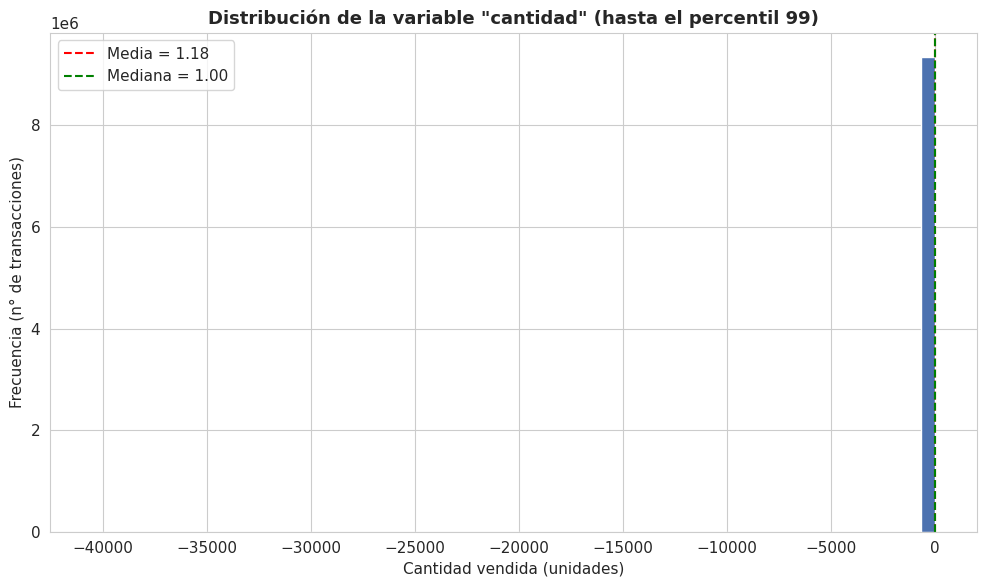

In [16]:
# Histograma de 'cantidad' (recortado al percentil 99 para legibilidad;
# la cola completa ya fue cuantificada en la sección 3.2)
fig, ax = plt.subplots(figsize=(10, 6))
limite_vis = cant.quantile(0.99)
ax.hist(cant[cant <= limite_vis], bins=60, color='#4C72B0', edgecolor='white')
ax.set_title('Distribución de la variable "cantidad" (hasta el percentil 99)')
ax.set_xlabel('Cantidad vendida (unidades)')
ax.set_ylabel('Frecuencia (n° de transacciones)')
ax.axvline(stats_cantidad['media'], color='red', linestyle='--', label=f"Media = {stats_cantidad['media']:.2f}")
ax.axvline(stats_cantidad['mediana'], color='green', linestyle='--', label=f"Mediana = {stats_cantidad['mediana']:.2f}")
ax.legend()
plt.tight_layout()
plt.show()


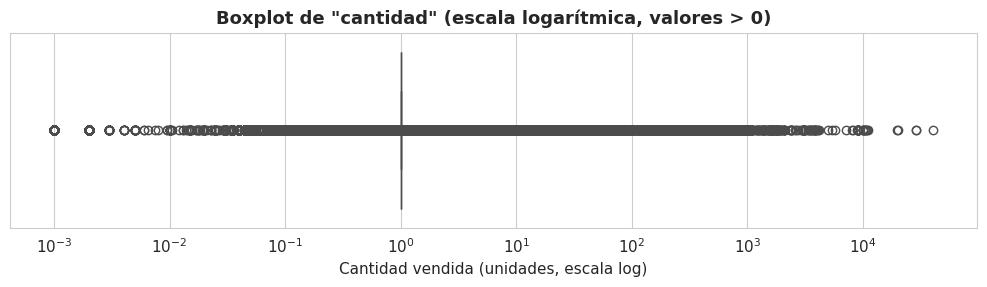

In [17]:
# Boxplot de 'cantidad' (escala logarítmica para visualizar la dispersión pese a los outliers)
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=cant[cant > 0], ax=ax, color='#4C72B0')
ax.set_xscale('log')
ax.set_title('Boxplot de "cantidad" (escala logarítmica, valores > 0)')
ax.set_xlabel('Cantidad vendida (unidades, escala log)')
plt.tight_layout()
plt.show()


In [18]:
asimetria = 'derecha (positiva)' if stats_cantidad['media'] > stats_cantidad['mediana'] else \
            'izquierda (negativa)' if stats_cantidad['media'] < stats_cantidad['mediana'] else 'aproximadamente simétrica'
dispersión = 'alta' if stats_cantidad['coef_variacion_%'] > 100 else 'moderada' if stats_cantidad['coef_variacion_%'] > 50 else 'baja'

display(Markdown(f'''
**Interpretación — variable `cantidad`:**
- Sobre **{stats_cantidad['n_registros']:,.0f}** registros, la cantidad promedio vendida por transacción es de **{stats_cantidad['media']:.2f} unidades**, con una mediana de **{stats_cantidad['mediana']:.2f}**.
- La relación entre media y mediana indica una distribución con asimetría hacia la **{asimetria}**, típica de datos de venta minorista donde predominan transacciones pequeñas y existe una cola de compras grandes (mayoristas/reposición).
- El coeficiente de variación es **{stats_cantidad['coef_variacion_%']:.1f}%**, lo que sugiere una dispersión **{dispersión}** relativa a la media.
- El rango intercuartílico es **{stats_cantidad['iqr']:.2f}** (P25 = {stats_cantidad['p25']:.2f}, P75 = {stats_cantidad['p75']:.2f}), mucho más acotado que el rango total (mín. {stats_cantidad['minimo']:.2f}, máx. {stats_cantidad['maximo']:.2f}), confirmando la presencia de valores extremos ya documentados en la sección 3.2.
'''))



**Interpretación — variable `cantidad`:**
- Sobre **9,447,662** registros, la cantidad promedio vendida por transacción es de **1.18 unidades**, con una mediana de **1.00**.
- La relación entre media y mediana indica una distribución con asimetría hacia la **derecha (positiva)**, típica de datos de venta minorista donde predominan transacciones pequeñas y existe una cola de compras grandes (mayoristas/reposición).
- El coeficiente de variación es **3523.6%**, lo que sugiere una dispersión **alta** relativa a la media.
- El rango intercuartílico es **0.00** (P25 = 1.00, P75 = 1.00), mucho más acotado que el rango total (mín. -40500.00, máx. 40500.00), confirmando la presencia de valores extremos ya documentados en la sección 3.2.


## 4.2 Variable `temperatura`

In [19]:
temp = df_final['temperatura']

stats_temp = {
    'n_registros': temp.count(),
    'media': temp.mean(),
    'mediana': temp.median(),
    'desv_estandar': temp.std(),
    'minimo': temp.min(),
    'maximo': temp.max(),
    'p25': temp.quantile(0.25),
    'p75': temp.quantile(0.75),
}
pd.Series(stats_temp).to_frame(name='temperatura (°C)')


,temperatura (°C)
n_registros,"9,447,662.00"
media,21.69
mediana,22.80
desv_estandar,5.37
minimo,6.40
maximo,32.90
p25,18.00
p75,25.80


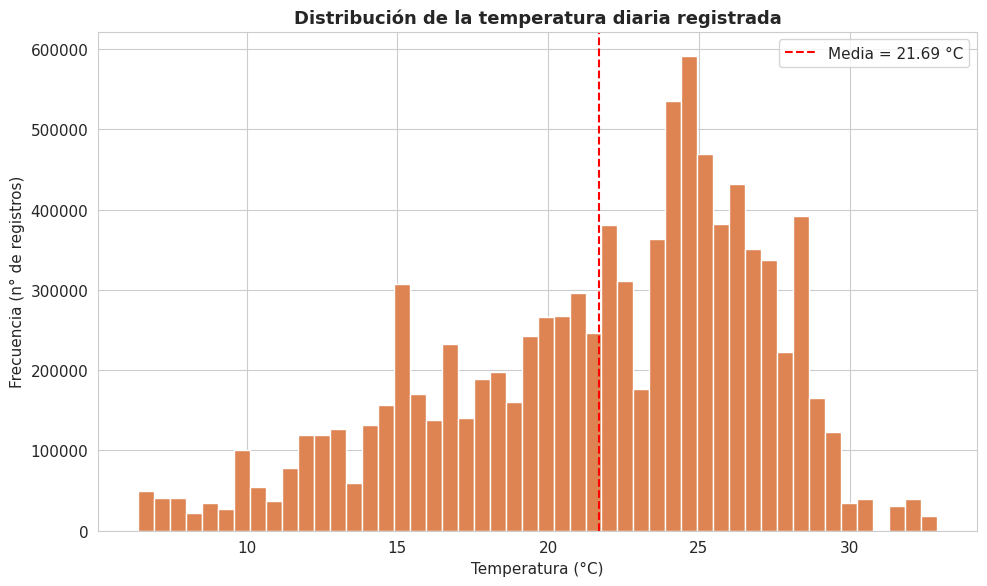

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(temp.dropna(), bins=50, color='#DD8452', edgecolor='white')
ax.set_title('Distribución de la temperatura diaria registrada')
ax.set_xlabel('Temperatura (°C)')
ax.set_ylabel('Frecuencia (n° de registros)')
ax.axvline(stats_temp['media'], color='red', linestyle='--', label=f"Media = {stats_temp['media']:.2f} °C")
ax.legend()
plt.tight_layout()
plt.show()


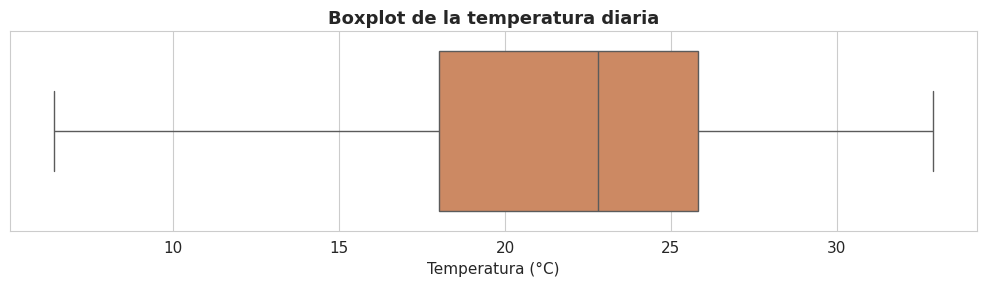

In [21]:
fig, ax = plt.subplots(figsize=(10, 3))
sns.boxplot(x=temp.dropna(), ax=ax, color='#DD8452')
ax.set_title('Boxplot de la temperatura diaria')
ax.set_xlabel('Temperatura (°C)')
plt.tight_layout()
plt.show()


In [22]:
rango_temp = stats_temp['maximo'] - stats_temp['minimo']
display(Markdown(f'''
**Interpretación — variable `temperatura`:**
- La temperatura registrada varía entre **{stats_temp['minimo']:.1f} °C** y **{stats_temp['maximo']:.1f} °C**, un rango de **{rango_temp:.1f} °C**.
- Media ({stats_temp['media']:.2f} °C) y mediana ({stats_temp['mediana']:.2f} °C) son {"muy cercanas, lo que sugiere una distribución relativamente simétrica" if abs(stats_temp['media'] - stats_temp['mediana']) < 1 else "distintas, lo que sugiere cierta asimetría en la distribución térmica"}, coherente con un clima subtropical con estacionalidad marcada.
- El rango intercuartílico (P25 = {stats_temp['p25']:.2f} °C, P75 = {stats_temp['p75']:.2f} °C) concentra la mayoría de los registros en un rango moderado, con colas hacia los extremos de invierno y verano.
'''))



**Interpretación — variable `temperatura`:**
- La temperatura registrada varía entre **6.4 °C** y **32.9 °C**, un rango de **26.5 °C**.
- Media (21.69 °C) y mediana (22.80 °C) son distintas, lo que sugiere cierta asimetría en la distribución térmica, coherente con un clima subtropical con estacionalidad marcada.
- El rango intercuartílico (P25 = 18.00 °C, P75 = 25.80 °C) concentra la mayoría de los registros en un rango moderado, con colas hacia los extremos de invierno y verano.


## 4.3 Variables categóricas

In [23]:
# --- desc_secciones ---
frec_secciones = df_final['desc_secciones'].value_counts()
frec_secciones_rel = (frec_secciones / len(df_final) * 100).round(2)
tabla_secciones = pd.DataFrame({'frecuencia_absoluta': frec_secciones, 'frecuencia_relativa_%': frec_secciones_rel})
tabla_secciones


,frecuencia_absoluta,frecuencia_relativa_%
desc_secciones,,
Perecederos,3817880,40.41
Almacen,2214370,23.44
Produccion,1170815,12.39
Limpieza,536005,5.67
Bazar,512456,5.42
Bebidas,427689,4.53
Belleza y Salud,376705,3.99
Insumos,233662,2.47
Tienda,151733,1.61


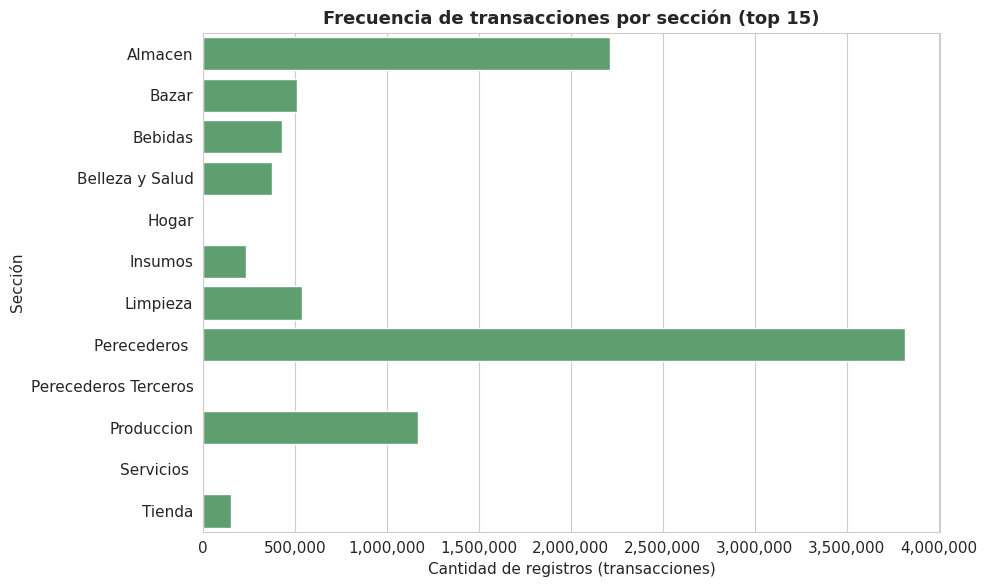

In [24]:
fig, ax = plt.subplots(figsize=(10, 6))
top_secciones = frec_secciones.head(15)
sns.barplot(x=top_secciones.values, y=top_secciones.index, ax=ax, color='#55A868')
ax.set_title('Frecuencia de transacciones por sección (top 15)')
ax.set_xlabel('Cantidad de registros (transacciones)')
ax.set_ylabel('Sección')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


In [25]:
# --- desc_categoria ---
frec_categoria = df_final['desc_categoria'].value_counts()
frec_categoria_rel = (frec_categoria / len(df_final) * 100).round(2)
tabla_categoria = pd.DataFrame({'frecuencia_absoluta': frec_categoria, 'frecuencia_relativa_%': frec_categoria_rel})
tabla_categoria.head(20)


,frecuencia_absoluta,frecuencia_relativa_%
desc_categoria,,
sin asignar.,2423943,25.66
Frescos,604577,6.40
Venta Al Mostrador,460411,4.87
Sachet,427621,4.53
Tetra,287783,3.05
Pote,213750,2.26
Verdeo,201680,2.13
Envasados,176095,1.86
Tomate,176044,1.86


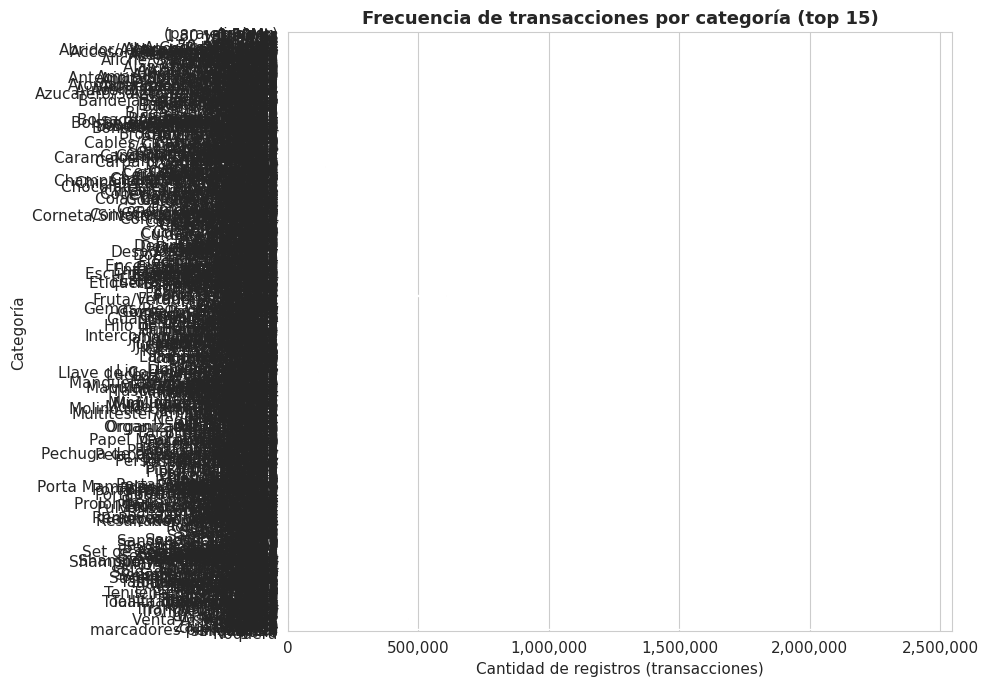

In [26]:
fig, ax = plt.subplots(figsize=(10, 7))
top_categorias = frec_categoria.head(15)
sns.barplot(x=top_categorias.values, y=top_categorias.index, ax=ax, color='#C44E52')
ax.set_title('Frecuencia de transacciones por categoría (top 15)')
ax.set_xlabel('Cantidad de registros (transacciones)')
ax.set_ylabel('Categoría')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


In [27]:
# --- local ---
frec_local = df_final['local'].value_counts()
frec_local_rel = (frec_local / len(df_final) * 100).round(2)
tabla_local = pd.DataFrame({'frecuencia_absoluta': frec_local, 'frecuencia_relativa_%': frec_local_rel})
tabla_local


,frecuencia_absoluta,frecuencia_relativa_%
local,,
Local X,6420811,67.96
Local Y,3026851,32.04


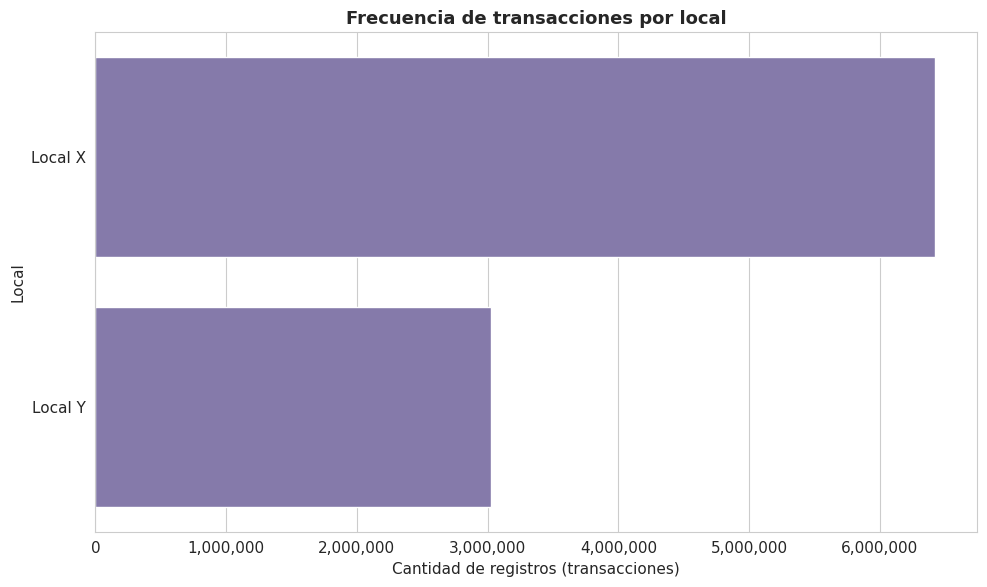

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=frec_local.values, y=frec_local.index, ax=ax, color='#8172B2')
ax.set_title('Frecuencia de transacciones por local')
ax.set_xlabel('Cantidad de registros (transacciones)')
ax.set_ylabel('Local')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


In [29]:
seccion_top = frec_secciones.index[0]
seccion_top_pct = frec_secciones_rel.iloc[0]
categoria_top = frec_categoria.index[0]
local_top = frec_local.index[0]
local_top_pct = frec_local_rel.iloc[0]
n_locales = df_final['local'].nunique()
n_secciones = df_final['desc_secciones'].nunique()
n_categorias = df_final['desc_categoria'].nunique()

display(Markdown(f'''
**Interpretación — variables categóricas:**
- El dataset abarca **{n_locales} locales**, **{n_secciones} secciones** y **{n_categorias} categorías** de producto.
- La sección con mayor peso transaccional es **"{seccion_top}"**, con **{seccion_top_pct:.1f}%** del total de registros.
- La categoría más frecuente es **"{categoria_top}"**.
- El local con mayor volumen de transacciones es **"{local_top}"** ({local_top_pct:.1f}% del total); {"la distribución entre locales es relativamente pareja" if (frec_local_rel.max() - frec_local_rel.min()) < 10 else "existe una diferencia notable en el volumen de transacciones entre locales"}, lo que debe tenerse en cuenta al comparar el efecto climático entre sucursales.
'''))



**Interpretación — variables categóricas:**
- El dataset abarca **2 locales**, **12 secciones** y **1189 categorías** de producto.
- La sección con mayor peso transaccional es **"Perecederos "**, con **40.4%** del total de registros.
- La categoría más frecuente es **"sin asignar."**.
- El local con mayor volumen de transacciones es **"Local X"** (68.0% del total); existe una diferencia notable en el volumen de transacciones entre locales, lo que debe tenerse en cuenta al comparar el efecto climático entre sucursales.


# 5. Análisis temporal

Todas las visualizaciones de esta sección se construyen sobre **agregaciones previas** (por fecha, mes o tipo de día), nunca sobre el detalle transaccional completo, para mantener el rendimiento con ~9.4M de filas.

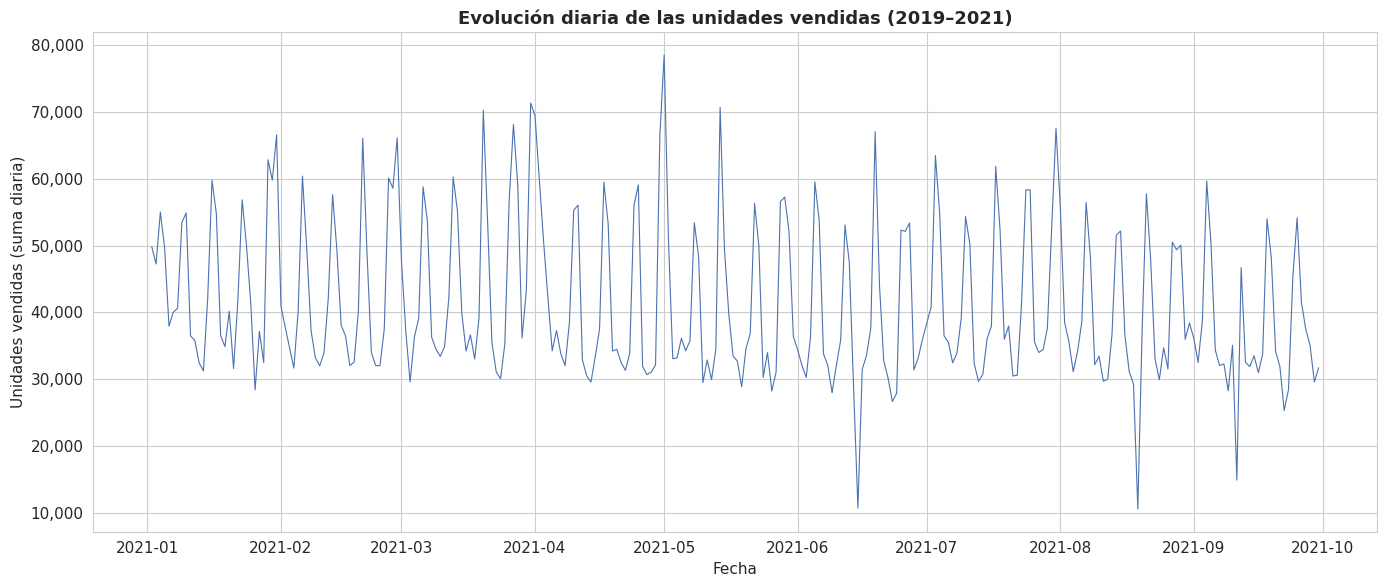

In [30]:
# Serie temporal de ventas agregadas por fecha (evita graficar el detalle transaccional)
ventas_diarias = df_final.groupby('fecha_vta', observed=True)['cantidad'].sum().sort_index()

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(ventas_diarias.index, ventas_diarias.values, color='#4C72B0', linewidth=0.8)
ax.set_title('Evolución diaria de las unidades vendidas (2019–2021)')
ax.set_xlabel('Fecha')
ax.set_ylabel('Unidades vendidas (suma diaria)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


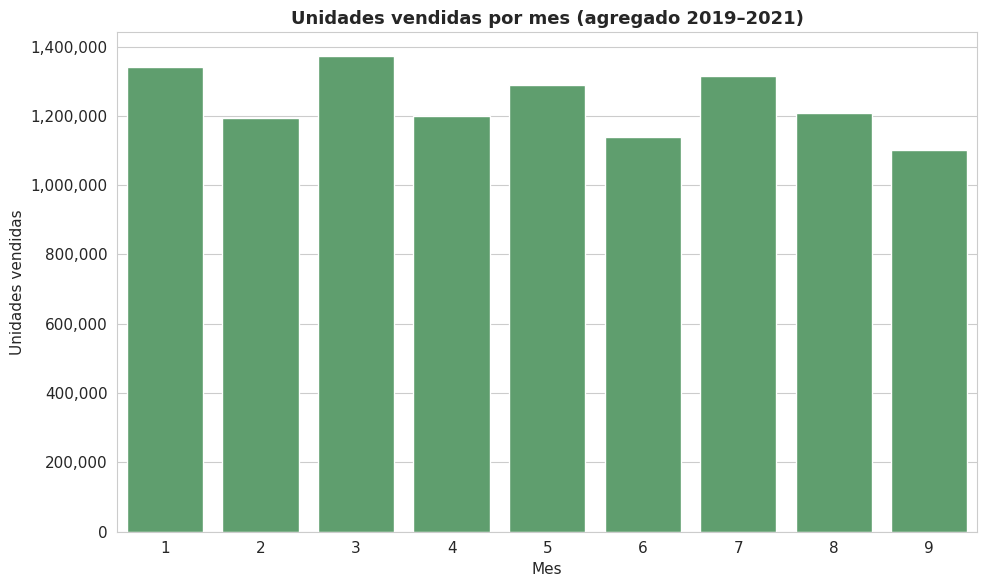

In [31]:
# Comportamiento mensual (agregado por mes, sumando los 3 años)
ventas_por_mes = df_final.groupby('mes', observed=True)['cantidad'].sum()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=ventas_por_mes.index, y=ventas_por_mes.values, ax=ax, color='#55A868')
ax.set_title('Unidades vendidas por mes (agregado 2019–2021)')
ax.set_xlabel('Mes')
ax.set_ylabel('Unidades vendidas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


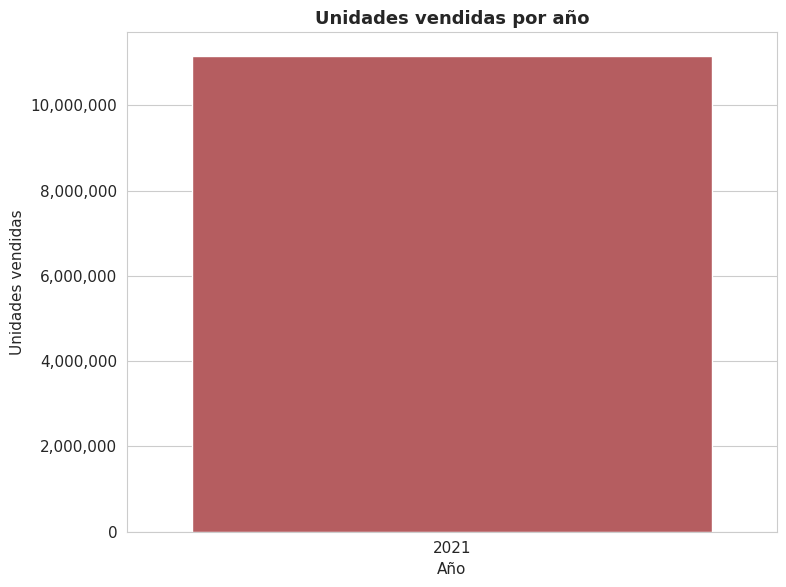

In [32]:
# Comportamiento por año
ventas_por_anio = df_final.groupby('anio', observed=True)['cantidad'].sum()

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=ventas_por_anio.index.astype(str), y=ventas_por_anio.values, ax=ax, color='#C44E52')
ax.set_title('Unidades vendidas por año')
ax.set_xlabel('Año')
ax.set_ylabel('Unidades vendidas')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


In [33]:
# Fin de semana vs días laborales
# Se compara el promedio de unidades vendidas por transacción y el total agregado por tipo de día
comparacion_finde = df_final.groupby('es_fin_de_semana', observed=True)['cantidad'].agg(['sum', 'mean', 'count'])
comparacion_finde.index = comparacion_finde.index.map({0: 'Día laboral', 1: 'Fin de semana'})
comparacion_finde.columns = ['total_unidades', 'promedio_por_transaccion', 'n_transacciones']
comparacion_finde


,total_unidades,promedio_por_transaccion,n_transacciones
es_fin_de_semana,,,
Día laboral,"6,911,828.50",1.17,5886267
Fin de semana,"4,246,378.00",1.19,3561395


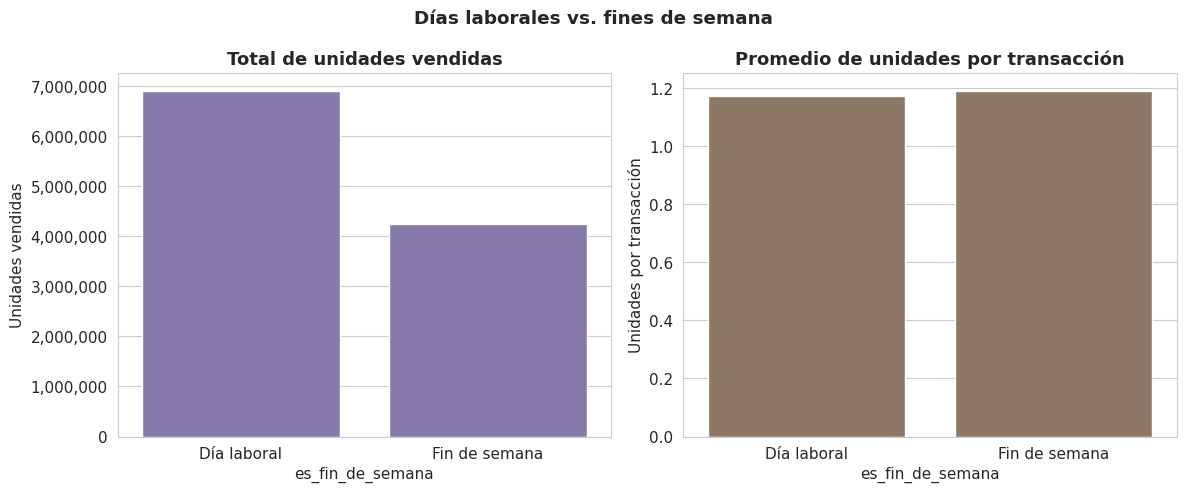

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=comparacion_finde.index, y=comparacion_finde['total_unidades'], ax=axes[0], color='#8172B2')
axes[0].set_title('Total de unidades vendidas')
axes[0].set_ylabel('Unidades vendidas')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

sns.barplot(x=comparacion_finde.index, y=comparacion_finde['promedio_por_transaccion'], ax=axes[1], color='#937860')
axes[1].set_title('Promedio de unidades por transacción')
axes[1].set_ylabel('Unidades por transacción')

fig.suptitle('Días laborales vs. fines de semana', fontweight='bold')
plt.tight_layout()
plt.show()


In [35]:
mes_max = ventas_por_mes.idxmax()
mes_min = ventas_por_mes.idxmin()
anio_max = ventas_por_anio.idxmax()
prom_finde = comparacion_finde.loc['Fin de semana', 'promedio_por_transaccion']
prom_laboral = comparacion_finde.loc['Día laboral', 'promedio_por_transaccion']
diff_finde_pct = (prom_finde - prom_laboral) / prom_laboral * 100

display(Markdown(f'''
**Interpretación — análisis temporal:**
- La serie diaria de ventas muestra la evolución completa del período 2019–2021 sin agregaciones que oculten quiebres puntuales (ej. inicios de pandemia, feriados extendidos), que conviene inspeccionar visualmente en el gráfico.
- El mes con mayor volumen agregado de ventas es **{mes_max}** y el de menor volumen es **{mes_min}**, lo que sugiere un componente estacional a contrastar más adelante con la temperatura promedio de esos meses.
- El año con mayor volumen total de unidades vendidas es **{anio_max}**.
- El promedio de unidades por transacción en fin de semana ({prom_finde:.2f}) es **{abs(diff_finde_pct):.1f}% {"mayor" if diff_finde_pct > 0 else "menor"}** que en días laborales ({prom_laboral:.2f}), lo que indica que el día de la semana **{"sí" if abs(diff_finde_pct) > 5 else "no parece"}** tener un efecto relevante sobre el tamaño promedio de la compra, un factor de calendario a controlar antes de atribuir variaciones al clima.
'''))



**Interpretación — análisis temporal:**
- La serie diaria de ventas muestra la evolución completa del período 2019–2021 sin agregaciones que oculten quiebres puntuales (ej. inicios de pandemia, feriados extendidos), que conviene inspeccionar visualmente en el gráfico.
- El mes con mayor volumen agregado de ventas es **3** y el de menor volumen es **9**, lo que sugiere un componente estacional a contrastar más adelante con la temperatura promedio de esos meses.
- El año con mayor volumen total de unidades vendidas es **2021**.
- El promedio de unidades por transacción en fin de semana (1.19) es **1.5% mayor** que en días laborales (1.17), lo que indica que el día de la semana **no parece** tener un efecto relevante sobre el tamaño promedio de la compra, un factor de calendario a controlar antes de atribuir variaciones al clima.


# 6. Análisis bivariado

## 6.1 Temperatura vs. ventas

In [36]:
# Agregación diaria: suma de unidades vendidas y temperatura promedio por fecha
agg_diario = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean')
).reset_index()

agg_diario.head()


,fecha_vta,cantidad_total,temperatura_promedio
0,2021-01-02,"49,828.31",26.86
1,2021-01-03,"47,241.14",28.20
2,2021-01-04,"55,018.26",27.27
3,2021-01-05,"49,575.00",24.49
4,2021-01-06,"37,930.74",26.55


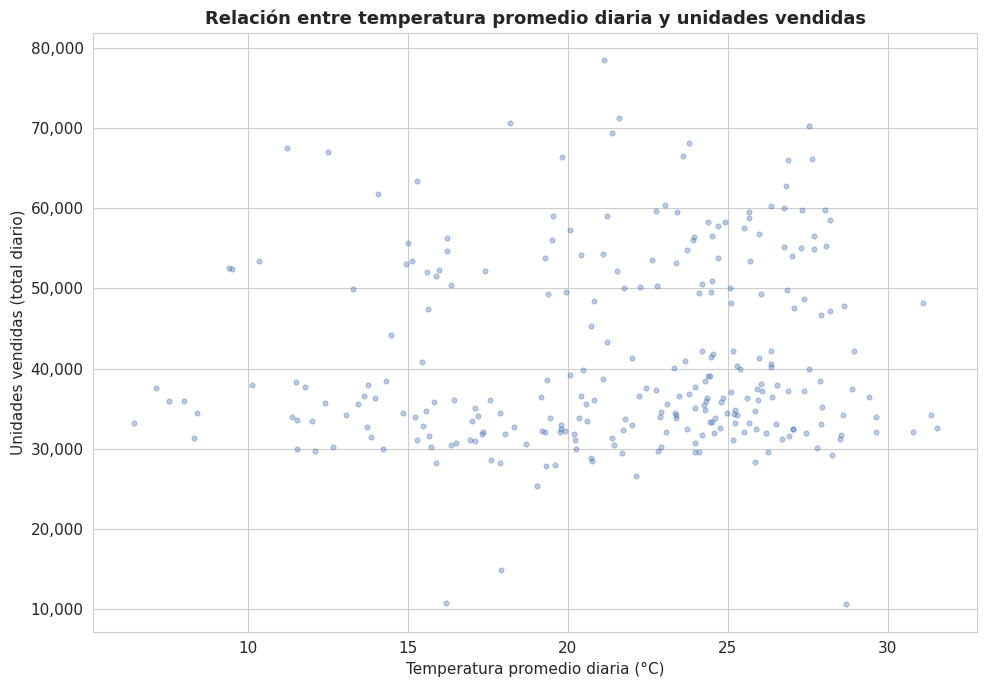

In [37]:
fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(agg_diario['temperatura_promedio'], agg_diario['cantidad_total'],
           alpha=0.35, s=12, color='#4C72B0')
ax.set_title('Relación entre temperatura promedio diaria y unidades vendidas')
ax.set_xlabel('Temperatura promedio diaria (°C)')
ax.set_ylabel('Unidades vendidas (total diario)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()


In [38]:
# Correlaciones sobre la serie agregada diaria (no sobre el detalle transaccional)
datos_corr = agg_diario.dropna(subset=['temperatura_promedio', 'cantidad_total'])
pearson_r, pearson_p = stats.pearsonr(datos_corr['temperatura_promedio'], datos_corr['cantidad_total'])
spearman_r, spearman_p = stats.spearmanr(datos_corr['temperatura_promedio'], datos_corr['cantidad_total'])

print(f"Correlación de Pearson : r = {pearson_r:.4f}  (p-valor = {pearson_p:.4g})")
print(f"Correlación de Spearman: rho = {spearman_r:.4f}  (p-valor = {spearman_p:.4g})")


Correlación de Pearson : r = 0.0859  (p-valor = 0.1583)
Correlación de Spearman: rho = 0.1198  (p-valor = 0.04885)


In [39]:
def calificar_intensidad(r):
    r_abs = abs(r)
    if r_abs < 0.1:
        return 'nula o muy débil'
    elif r_abs < 0.3:
        return 'débil'
    elif r_abs < 0.5:
        return 'moderada'
    elif r_abs < 0.7:
        return 'fuerte'
    else:
        return 'muy fuerte'

direccion = 'positiva (a mayor temperatura, más ventas)' if pearson_r > 0 else \
            'negativa (a mayor temperatura, menos ventas)' if pearson_r < 0 else 'nula'
intensidad = calificar_intensidad(pearson_r)
significativo = pearson_p < 0.05

display(Markdown(f'''
**Interpretación — temperatura vs. ventas:**
- La correlación de Pearson entre temperatura promedio diaria y unidades vendidas es **r = {pearson_r:.3f}** ({"estadísticamente significativa" if significativo else "no estadísticamente significativa"} al 5%, p = {pearson_p:.4g}).
- La correlación de Spearman (rho = {spearman_r:.3f}) {"confirma un patrón similar, lo que sugiere que la relación no depende fuertemente de outliers puntuales" if abs(spearman_r - pearson_r) < 0.1 else "difiere de la de Pearson, lo que sugiere una relación no estrictamente lineal o sensible a valores atípicos"}.
- La relación observada es de dirección **{direccion}** e intensidad **{intensidad}**.
- **Limitación importante:** esta correlación es agregada a nivel diario y **no controla factores de calendario** (fin de semana, feriados, estacionalidad de fin de mes) ni diferencias entre locales. **Correlación no implica causalidad**: una relación entre temperatura y ventas puede estar mediada por la estacionalidad del calendario (ej. meses cálidos que coinciden con vacaciones). El aislamiento de estos factores queda para la fase inferencial/de modelado.
'''))



**Interpretación — temperatura vs. ventas:**
- La correlación de Pearson entre temperatura promedio diaria y unidades vendidas es **r = 0.086** (no estadísticamente significativa al 5%, p = 0.1583).
- La correlación de Spearman (rho = 0.120) confirma un patrón similar, lo que sugiere que la relación no depende fuertemente de outliers puntuales.
- La relación observada es de dirección **positiva (a mayor temperatura, más ventas)** e intensidad **nula o muy débil**.
- **Limitación importante:** esta correlación es agregada a nivel diario y **no controla factores de calendario** (fin de semana, feriados, estacionalidad de fin de mes) ni diferencias entre locales. **Correlación no implica causalidad**: una relación entre temperatura y ventas puede estar mediada por la estacionalidad del calendario (ej. meses cálidos que coinciden con vacaciones). El aislamiento de estos factores queda para la fase inferencial/de modelado.


## 6.2 Lluvia/clima vs. ventas




In [40]:
columnas_clima_disponibles = [c for c in df_final.columns if 'lluvia' in c.lower() or 'precipita' in c.lower()
                               or 'clima' in c.lower() or 'temperatura' in c.lower()]
print("Columnas relacionadas con clima detectadas en df_final:")
print(columnas_clima_disponibles)


Columnas relacionadas con clima detectadas en df_final:
['temperatura']


## 6.3 Categorías vs. temperatura

In [41]:
# Definición de grupos climáticos según terciles de la temperatura observada
# (se usan terciles, en lugar de umbrales fijos arbitrarios, para que los grupos
#  reflejen la distribución real registrada en las estaciones del dataset)
t_bajo, t_alto = df_final['temperatura'].quantile([1/3, 2/3])

def clasificar_clima(t):
    if pd.isna(t):
        return np.nan
    elif t <= t_bajo:
        return 'Frío'
    elif t <= t_alto:
        return 'Templado'
    else:
        return 'Caluroso'

df_final['grupo_climatico'] = df_final['temperatura'].apply(clasificar_clima).astype('category')

print(f"Umbral Frío/Templado: {t_bajo:.2f} °C | Umbral Templado/Caluroso: {t_alto:.2f} °C")
df_final['grupo_climatico'].value_counts()


Umbral Frío/Templado: 20.00 °C | Umbral Templado/Caluroso: 24.90 °C


,count
grupo_climatico,
Templado,3255088
Frío,3157077
Caluroso,3035497


In [42]:
# Ventas promedio por categoría y grupo climático (agregación previa a graficar)
secciones_interes = frec_secciones.head(6).index.tolist()  # top 6 secciones por volumen

ventas_seccion_clima = (
    df_final[df_final['desc_secciones'].isin(secciones_interes)]
    .groupby(['desc_secciones', 'grupo_climatico'], observed=True)['cantidad']
    .mean()
    .reset_index()
)

tabla_pivot = ventas_seccion_clima.pivot(index='desc_secciones', columns='grupo_climatico', values='cantidad')
tabla_pivot = tabla_pivot[['Frío', 'Templado', 'Caluroso']]
tabla_pivot


grupo_climatico,Frío,Templado,Caluroso
desc_secciones,,,
Almacen,1.20,1.19,1.19
Bazar,1.25,1.23,1.24
Bebidas,1.39,1.46,1.47
Limpieza,1.05,1.06,1.06
Perecederos,1.16,1.17,1.18
Produccion,1.09,1.08,1.06


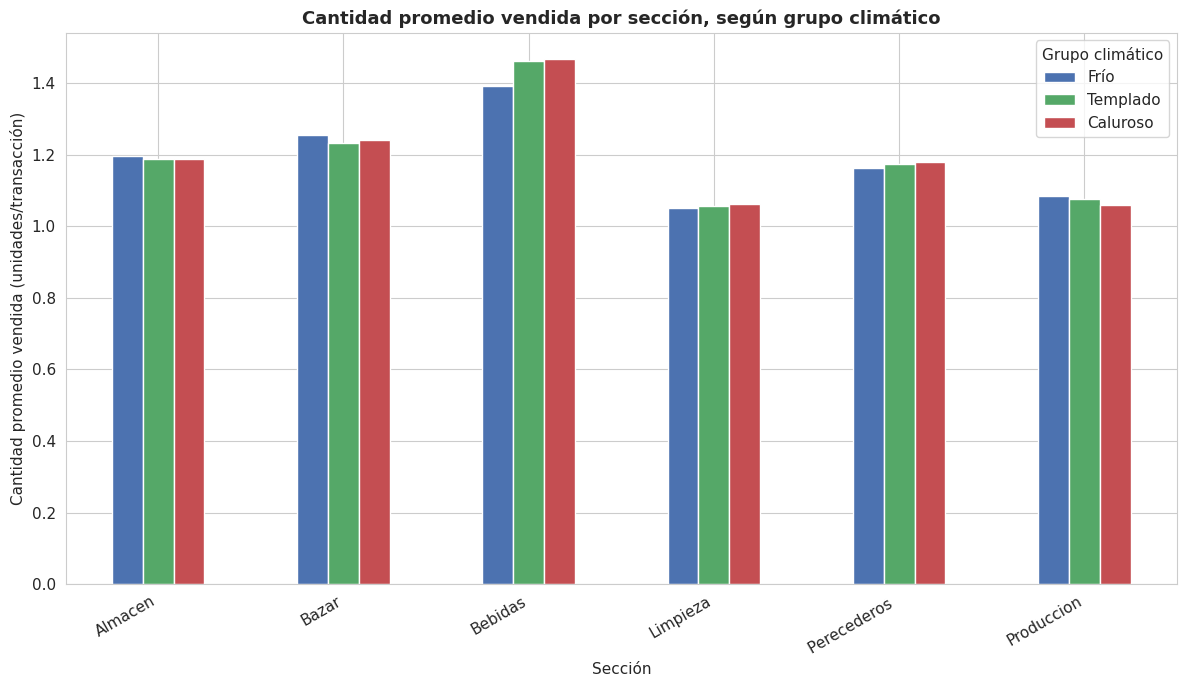

In [43]:
fig, ax = plt.subplots(figsize=(12, 7))
tabla_pivot.plot(kind='bar', ax=ax, color=['#4C72B0', '#55A868', '#C44E52'])
ax.set_title('Cantidad promedio vendida por sección, según grupo climático')
ax.set_xlabel('Sección')
ax.set_ylabel('Cantidad promedio vendida (unidades/transacción)')
ax.legend(title='Grupo climático')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


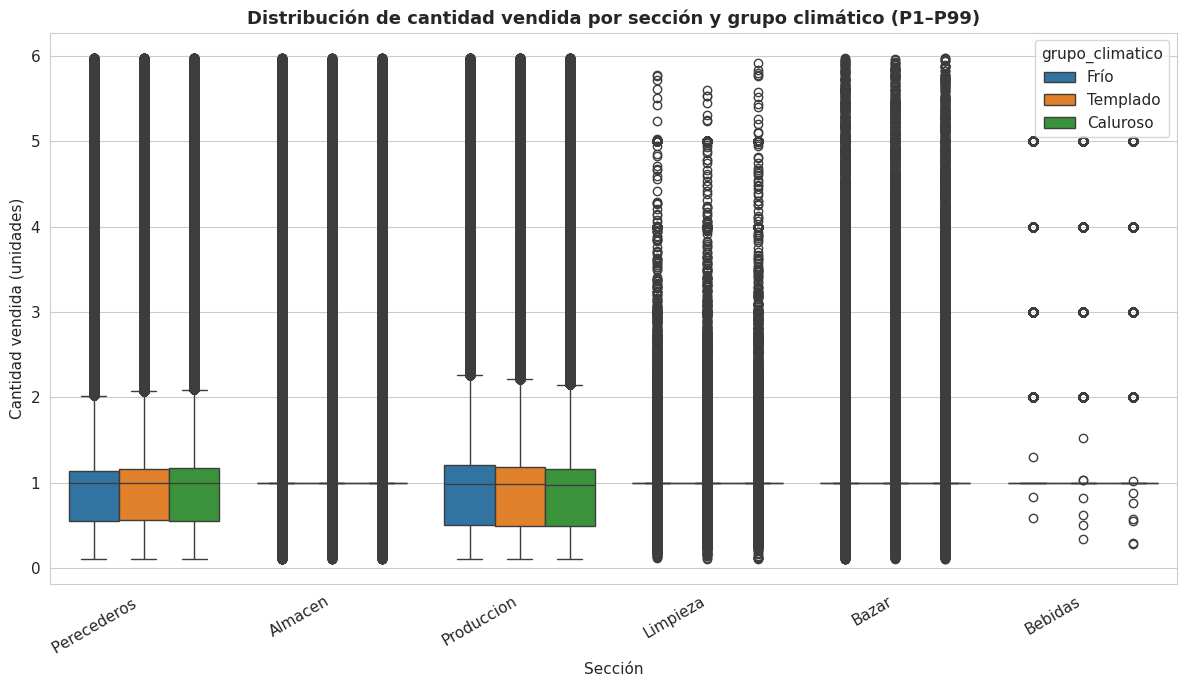

In [44]:
# Boxplot de cantidad por grupo climático para las secciones de interés
fig, ax = plt.subplots(figsize=(12, 7))
muestra_boxplot = df_final[df_final['desc_secciones'].isin(secciones_interes)]
sns.boxplot(
    data=muestra_boxplot[muestra_boxplot['cantidad'].between(
        muestra_boxplot['cantidad'].quantile(0.01), muestra_boxplot['cantidad'].quantile(0.99)
    )],
    x='desc_secciones', y='cantidad', hue='grupo_climatico',
    order=secciones_interes, hue_order=['Frío', 'Templado', 'Caluroso'], ax=ax
)
ax.set_title('Distribución de cantidad vendida por sección y grupo climático (P1–P99)')
ax.set_xlabel('Sección')
ax.set_ylabel('Cantidad vendida (unidades)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


In [45]:
# Variación porcentual Caluroso vs. Frío por sección: útil para detectar sustitución/venta cruzada
tabla_pivot['variacion_caluroso_vs_frio_%'] = (
    (tabla_pivot['Caluroso'] - tabla_pivot['Frío']) / tabla_pivot['Frío'] * 100
).round(2)

tabla_variacion = tabla_pivot['variacion_caluroso_vs_frio_%'].sort_values()
tabla_variacion


,variacion_caluroso_vs_frio_%
desc_secciones,
Produccion,-2.40
Bazar,-1.12
Almacen,-0.64
Limpieza,1.20
Perecederos,1.31
Bebidas,5.46


In [46]:
seccion_mas_sensible_baja = tabla_variacion.index[0]
var_baja = tabla_variacion.iloc[0]
seccion_mas_sensible_alta = tabla_variacion.index[-1]
var_alta = tabla_variacion.iloc[-1]

display(Markdown(f'''
**Interpretación — categorías vs. temperatura:**
- Los locales fueron agrupados en tres bandas climáticas (Frío ≤ {t_bajo:.1f} °C, Templado, Caluroso > {t_alto:.1f} °C) usando terciles de la temperatura observada.
- La sección con **mayor caída relativa** de ventas promedio entre días calurosos y fríos es **"{seccion_mas_sensible_baja}"** ({var_baja:+.1f}%).
- La sección con **mayor aumento relativo** en días calurosos es **"{seccion_mas_sensible_alta}"** ({var_alta:+.1f}%).
- {"Este patrón —una sección que cae mientras otra sube con la temperatura— es consistente con un efecto de sustitución o venta cruzada entre categorías (ej. bebidas calientes vs. frías) y constituye un candidato directo para las hipótesis de la fase inferencial." if var_alta > 0 and var_baja < 0 else "En esta agregación no se observa un patrón claro de sustitución (secciones que suben y bajan simultáneamente); esto no descarta el efecto, ya que puede estar diluido al nivel de sección y ser más visible a nivel de categoría o producto específico."}
- Estos resultados son descriptivos: no se ha controlado por local, mes ni día de semana, por lo que deben tomarse como evidencia preliminar, no concluyente.
'''))



**Interpretación — categorías vs. temperatura:**
- Los locales fueron agrupados en tres bandas climáticas (Frío ≤ 20.0 °C, Templado, Caluroso > 24.9 °C) usando terciles de la temperatura observada.
- La sección con **mayor caída relativa** de ventas promedio entre días calurosos y fríos es **"Produccion"** (-2.4%).
- La sección con **mayor aumento relativo** en días calurosos es **"Bebidas"** (+5.5%).
- Este patrón —una sección que cae mientras otra sube con la temperatura— es consistente con un efecto de sustitución o venta cruzada entre categorías (ej. bebidas calientes vs. frías) y constituye un candidato directo para las hipótesis de la fase inferencial.
- Estos resultados son descriptivos: no se ha controlado por local, mes ni día de semana, por lo que deben tomarse como evidencia preliminar, no concluyente.


# 7. Matriz de correlación

La matriz se construye sobre la **agregación diaria** (una fila por fecha), no sobre el detalle transaccional, ya que `dia_semana` y `mes` son atributos del calendario y no varían dentro de un mismo día.

In [47]:
# Reconstrucción de la agregación diaria incluyendo variables de calendario
agg_calendario = df_final.groupby('fecha_vta', observed=True).agg(
    cantidad_total=('cantidad', 'sum'),
    temperatura_promedio=('temperatura', 'mean'),
    mes=('mes', 'first'),
    anio=('anio', 'first'),
    es_fin_de_semana=('es_fin_de_semana', 'first'),
    es_feriado=('es_feriado', 'first'),
).reset_index()

# dia_semana como número (0=Lunes) para poder incluirlo en la matriz numérica
agg_calendario['dia_semana_num'] = agg_calendario['fecha_vta'].dt.dayofweek

cols_corr = ['cantidad_total', 'temperatura_promedio', 'mes', 'dia_semana_num',
             'es_fin_de_semana', 'es_feriado']
matriz_corr = agg_calendario[cols_corr].corr(method='pearson')
matriz_corr


,cantidad_total,temperatura_promedio,mes,dia_semana_num,es_fin_de_semana,es_feriado
cantidad_total,1.00,0.09,-0.19,0.65,0.73,0.23
temperatura_promedio,0.09,1.00,-0.41,0.02,0.07,0.00
mes,-0.19,-0.41,1.00,-0.01,-0.02,0.03
dia_semana_num,0.65,0.02,-0.01,1.00,0.79,0.07
es_fin_de_semana,0.73,0.07,-0.02,0.79,1.00,0.11
es_feriado,0.23,0.00,0.03,0.07,0.11,1.00


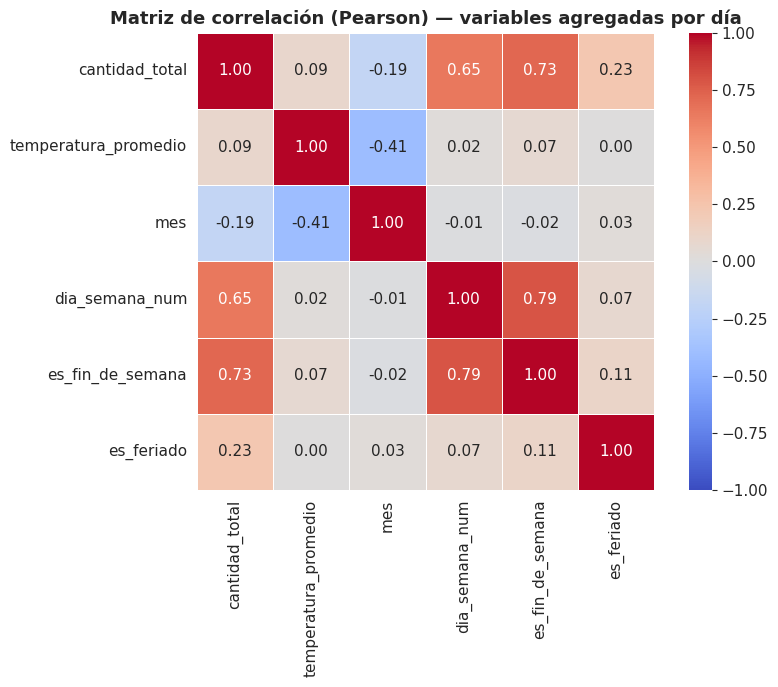

In [48]:
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title('Matriz de correlación (Pearson) — variables agregadas por día')
plt.tight_layout()
plt.show()


In [49]:
corr_con_ventas = matriz_corr['cantidad_total'].drop('cantidad_total').sort_values(key=abs, ascending=False)
variable_mas_relacionada = corr_con_ventas.index[0]
valor_mas_relacionada = corr_con_ventas.iloc[0]

display(Markdown(f'''
**Interpretación — matriz de correlación:**
- De las variables analizadas, la que muestra **mayor asociación lineal** con `cantidad_total` es **`{variable_mas_relacionada}`** (r = {valor_mas_relacionada:.3f}).
- La correlación entre `temperatura_promedio` y `cantidad_total` es **r = {matriz_corr.loc['temperatura_promedio','cantidad_total']:.3f}**, consistente con lo hallado en la sección 6.1.
- Las variables de calendario (`es_fin_de_semana`, `es_feriado`, `mes`, `dia_semana_num`) muestran correlaciones {"bajas" if corr_con_ventas.drop(variable_mas_relacionada, errors="ignore").abs().max() < 0.3 else "no despreciables"} con las ventas, lo que refuerza la necesidad de **controlar estos factores simultáneamente** (por ejemplo, con un modelo de regresión múltiple) antes de atribuir variaciones de venta al clima.
'''))



**Interpretación — matriz de correlación:**
- De las variables analizadas, la que muestra **mayor asociación lineal** con `cantidad_total` es **`es_fin_de_semana`** (r = 0.726).
- La correlación entre `temperatura_promedio` y `cantidad_total` es **r = 0.086**, consistente con lo hallado en la sección 6.1.
- Las variables de calendario (`es_fin_de_semana`, `es_feriado`, `mes`, `dia_semana_num`) muestran correlaciones no despreciables con las ventas, lo que refuerza la necesidad de **controlar estos factores simultáneamente** (por ejemplo, con un modelo de regresión múltiple) antes de atribuir variaciones de venta al clima.


# 8. Resumen de hallazgos

In [50]:
display(Markdown(f'''
### Principales patrones encontrados

1. **Distribución de `cantidad`:** asimetría hacia la {asimetria}, con coeficiente de variación de {stats_cantidad['coef_variacion_%']:.1f}%, lo que indica alta heterogeneidad en el tamaño de las transacciones.
2. **Estacionalidad temporal:** el mes de mayor volumen de ventas es {mes_max} y el de menor volumen es {mes_min}; el promedio de unidades por transacción en fin de semana difiere en {diff_finde_pct:+.1f}% respecto a los días laborales.
3. **Relación clima-ventas:** la correlación (Pearson) entre temperatura promedio diaria y unidades vendidas es de {pearson_r:.3f} ({intensidad}, {"significativa" if significativo else "no significativa"} al 5%).
4. **Sensibilidad por sección:** "{seccion_mas_sensible_alta}" incrementa sus ventas promedio {var_alta:+.1f}% en días calurosos frente a fríos, mientras que "{seccion_mas_sensible_baja}" varía {var_baja:+.1f}%.
5. **Rol del calendario:** las variables de calendario (fin de semana, feriado, mes) presentan una correlación con las ventas que debe controlarse junto con el clima para no confundir ambos efectos.

### Variables que parecen relacionarse con las ventas
- `temperatura_promedio` (relación {intensidad}).
- `mes` / estacionalidad calendario.
- `es_fin_de_semana`.
- `desc_secciones` / `desc_categoria` como moderadores del efecto climático (el clima no afecta a todas las secciones por igual).

### Categorías más sensibles al clima (evidencia preliminar)
- Mayor sensibilidad positiva a la temperatura: **{seccion_mas_sensible_alta}**.
- Mayor sensibilidad negativa a la temperatura: **{seccion_mas_sensible_baja}**.
'''))



### Principales patrones encontrados

1. **Distribución de `cantidad`:** asimetría hacia la derecha (positiva), con coeficiente de variación de 3523.6%, lo que indica alta heterogeneidad en el tamaño de las transacciones.
2. **Estacionalidad temporal:** el mes de mayor volumen de ventas es 3 y el de menor volumen es 9; el promedio de unidades por transacción en fin de semana difiere en +1.5% respecto a los días laborales.
3. **Relación clima-ventas:** la correlación (Pearson) entre temperatura promedio diaria y unidades vendidas es de 0.086 (nula o muy débil, no significativa al 5%).
4. **Sensibilidad por sección:** "Bebidas" incrementa sus ventas promedio +5.5% en días calurosos frente a fríos, mientras que "Produccion" varía -2.4%.
5. **Rol del calendario:** las variables de calendario (fin de semana, feriado, mes) presentan una correlación con las ventas que debe controlarse junto con el clima para no confundir ambos efectos.

### Variables que parecen relacionarse con las ventas
- `temperatura_promedio` (relación nula o muy débil).
- `mes` / estacionalidad calendario.
- `es_fin_de_semana`.
- `desc_secciones` / `desc_categoria` como moderadores del efecto climático (el clima no afecta a todas las secciones por igual).

### Categorías más sensibles al clima (evidencia preliminar)
- Mayor sensibilidad positiva a la temperatura: **Bebidas**.
- Mayor sensibilidad negativa a la temperatura: **Produccion**.


### Hipótesis para la fase inferencial

**H1:** Las ventas promedio de la sección más sensible detectada presentan diferencias estadísticamente significativas según el grupo climático (frío / templado / caluroso), controlando por local.

**H2:** Existe una asociación significativa entre la temperatura diaria y la cantidad total vendida, incluso después de controlar por variables de calendario (fin de semana, feriado, mes).

**H3:** El efecto de la temperatura sobre las ventas difiere significativamente entre secciones comerciales, evidenciando un patrón de sustitución (ej. bebidas frías vs. calientes) más que un efecto homogéneo sobre el total de ventas.

**H4:** El día de la semana (particularmente fin de semana) modera la magnitud del efecto climático sobre las ventas, siendo más marcado en días de mayor afluencia.

**H5:** El efecto climático sobre las ventas varía por local, en función de la estación meteorológica asignada y su perfil de temperaturas.

### Conclusiones preliminares de la Fase 1

- El dataset integrado (`df_final`) tiene calidad suficiente para el análisis: los nulos detectados en el perfilado original son estructurales (meses con menos de 31 días) y ya fueron resueltos en la etapa de preparación; no se identificaron problemas de integridad adicionales que impidan avanzar.
- Existe evidencia descriptiva de una relación entre temperatura y ventas, pero de magnitud que debe confirmarse estadísticamente controlando por calendario y local antes de afirmar causalidad.
- El nivel de sección/categoría es el más prometedor para detectar efectos de sustitución o venta cruzada, más que el total agregado de ventas.
- Los siguientes pasos (Fase 2/3 de CRISP-DM) deberían incluir modelos de regresión (u otro método de control estadístico) que aíslen el efecto climático del efecto de calendario y de local, tomando como base las hipótesis H1–H5 planteadas arriba.
